In [6]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(Path.cwd()).resolve().parent.parent
RESULTS_DIR = PROJECT_ROOT / "data" / "results"

In [7]:

final_measures = [
    'std', #Valence Variability
    'diff_std', #Valence Change Variability
    'mean', #Mean Valence
    'polarity_index', #polarity index
    'emotion_polarity_index', #emotion polarity index
    'tone_polarity_index', #tone polarity index
    'neg_ratio', #Negative Valence Frequency
    'negemo', #Negative Emotion Frequency
    'negtone', #Negative Tone Frequency
    'pos_ratio', #Positive Valence Frequency
    'posemo', #Positive Emotion Frequency
    'postone', #Positive Tone Frequency
    'min',
    'max', 
    'lexicon_word_ratio', #Valence Frequency
    'emotion_frequency', #Emotion Frequency
    'tone_frequency', #Tone Frequency
    'lexicon_word_count', #Valence Count
    'response_word_count', #Total Count
    'emotion_count', #Emotion Count
    'tone_count', #Tone Count
]

measure_title = {
    # Affective Instability
    'std': 'Valence Variability (VADER)',
    'diff_std': 'Valence Change Variability (VADER)',
    # Overall affective orientation
    'mean': 'Mean Valence (VADER)',
    'polarity_index': 'Polarity Index (VADER)',
    'emotion_polarity_index': 'Emotion Polarity Index (LIWC)',
    'tone_polarity_index': 'Tone Polarity Index (LIWC)',
    # Degree of Negative Affect
    'neg_ratio': 'Negative Valence Frequency (VADER)',
    'negemo': 'Negative Emotion Frequency (LIWC)',
    'negtone': 'Negative Tone Frequency (LIWC)',
    #'negative_mean': 'Negative Valence Intensity',
    # Degree of Positive Affect
    'pos_ratio': 'Positive Valence Frequency (VADER)',
    'posemo': 'Positive Emotion Frequency (LIWC)',
    'postone': 'Positive Tone Frequency (LIWC)',
    #'positive_mean': 'Positive Valence Intensity',
    # Affectve Extremes
    'min': 'Minimum Valence (VADER)',
    'max': 'Maximum Valence (VADER)',
    # Emotional Density
    'lexicon_word_ratio': 'Valence Frequency (VADER)',
    'emotion_frequency': 'Emotion Frequency (LIWC)',
    'tone_frequency': 'Tone Frequency (LIWC)',
    # Verbosity Controls
    'lexicon_word_count': 'Valence Word Count (VADER)',
    'response_word_count': 'Total Word Count (VADER)',
    'emotion_count': 'Emotion Word Count (LIWC)',
    'tone_count': 'Tone Word Count (LIWC)',
    # Ground Truth
    'identity_sum': 'Identity Sum Score',
    'identity_overall': 'Identity Overall Score',
}
measure_groups = {
    'Affective Variability': ['std', 'diff_std'],
    'Overall Affective Orientation': ['mean', 'polarity_index', 'emotion_polarity_index', 'tone_polarity_index'],
    'Negative Affect Usage': ['neg_ratio', 'negemo', 'negtone'],
    'Positive Affect Usage': ['pos_ratio', 'posemo', 'postone'],
    'Affective Extremes': ['min', 'max'],
    'Affective Expressiveness': ['lexicon_word_ratio', 'emotion_frequency', 'tone_frequency'],
    'Verbosity Controls': ['lexicon_word_count', 'response_word_count', 'emotion_count', 'tone_count']
}

In [ ]:
import pandas as pd
import re
df_vader = pd.read_excel(RESULTS_DIR / "sentiment_vader.xlsx")
df_liwc = pd.read_csv(RESULTS_DIR / "results_liwc22.csv")

metadata = [
    "subject_id",
    "identity_sum",
    "identity_total_sum",
    "stipo_en1",
    "stipo_en2",
    "stipo_en3",
    "stipo_en4",
    "stipo_sw1",
    "stipo_sw2",
    "stipo_sw3",
    "stipo_sw4",
    "stipo_sw5",
    "stipo_sw6",
    "stipo_sw7",
    "stipo_ow1",
    "stipo_ow2",
    "stipo_ow3",
    "stipo_ow4",
    "identity_overall",
    "narcissism_overall",
    "structure_level_overall",
    "engagement_total",
    "self_perception_total",
    "object_perception_total",
    "patient_control",
    "response_count_total",
    "missing_qids",
]

suffixes = ["vader", "gervader", "liwc22", "deliwc15"] #"liwc15" just for supplementary analyses, not in main paper
lang_map = {
    "vader": "english",
    "liwc22": "english",
    "liwc15": "english",
    "deliwc15": "german",
    "gervader": "german",
}

In [ ]:
pattern = re.compile(r"^(.+)_(mean|total)_(" + "|".join(suffixes) + r")$")

# Keep only metadata cols + cols matching the pattern
keep_cols = [c for c in df.columns if c in metadata or pattern.match(c)]
df = df[keep_cols]

# Melt to long format
id_vars = [c for c in df.columns if c in metadata]
value_vars = [c for c in df.columns if c not in metadata]

df_long = df.melt(id_vars=id_vars, value_vars=value_vars, var_name="column", value_name="value")

def parse_col(col):
    m = pattern.match(col)
    return m.group(1), m.group(2), m.group(3)  # measure, aggregation, suffix

df_long[["measure", "aggregation", "suffix"]] = df_long["column"].apply(
    lambda c: pd.Series(parse_col(c))
)
df_long = df_long.drop(columns="column")
df_long["language"] = df_long["suffix"].map(lang_map)

df_long = df_long[df_long["measure"].isin(final_measures)].copy()  # filter to just the measures we want to test

df_long.to_excel("data/final_results_long_full.xlsx", index=False)
df_long.columns


Index(['subject_id', 'identity_sum', 'identity_total_sum', 'stipo_en1',
       'stipo_en2', 'stipo_en3', 'stipo_en4', 'stipo_sw1', 'stipo_sw2',
       'stipo_sw3', 'stipo_sw4', 'stipo_sw5', 'stipo_sw6', 'stipo_sw7',
       'stipo_ow1', 'stipo_ow2', 'stipo_ow3', 'stipo_ow4', 'identity_overall',
       'narcissism_overall', 'structure_level_overall', 'engagement_total',
       'self_perception_total', 'object_perception_total', 'patient_control',
       'response_count_total', 'missing_qids', 'value', 'measure',
       'aggregation', 'suffix', 'language'],
      dtype='object')

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
import matplotlib.patches as mpatches
from scipy import stats

# ── adapt these to your actual column names ────────────────────────────────
MEASURE_COL   = 'measure'        # column with measure names
LANGUAGE_COL  = 'language'       # column with language labels
FEATURE_COL   = 'value'          # column with the linguistic score
PEARSON_TARGET  = 'identity_sum'
SPEARMAN_TARGET = 'identity_overall'

LANG_ENGLISH = 'english'         # exact string in your language column
LANG_GERMAN  = 'german'          # exact string in your language column

COLORS = {LANG_ENGLISH: '#2166ac', LANG_GERMAN: '#d6604d'}
COLORS = {LANG_ENGLISH: 'black', LANG_GERMAN: '#c0392b'}
MARKERS = {LANG_ENGLISH: 'o', LANG_GERMAN: 'D'}   # circle vs diamond
LANG_OFFSET = {LANG_ENGLISH: -0.12, LANG_GERMAN: +0.12}

# order rows top→bottom; set to None for alphabetical
MEASURES_ORDER = final_measures  # or e.g. ['vader_pos', 'vader_neg', 'liwc_anx', ...]

print("No. of rows with mean aggregation:", (df_long[df_long['aggregation'] == 'mean'].shape[0])//72)

german = df_long["language"] == "german"
df_long.loc[german & (df_long["measure"] == "posemo"), "measure"] = "postone"
df_long.loc[german & (df_long["measure"] == "negemo"), "measure"] = "negtone"
df_long.loc[german & (df_long["measure"] == "emotion_frequency"), "measure"] = "tone_frequency"
df_long.loc[german & (df_long["measure"] == "emotion_count"), "measure"] = "tone_count"
df_long.loc[german & (df_long["measure"] == "emotion_polarity_index"), "measure"] = "tone_polarity_index"

df_mean = df_long[df_long['aggregation'] == 'mean']
df_long.loc[df_long[MEASURE_COL].isin(["min", "max"]), "aggregation"] = "total"
df_long = df_long[df_long["aggregation"] == "total"].copy()  # filter to just the mean-aggregated measures

No. of rows with mean aggregation: 22


## Correlation + Fisher-z 95% CI

In [ ]:
N_BOOT = 5000
RNG = np.random.default_rng(42)

records = []

for (measure, lang), grp in df_long.groupby([MEASURE_COL, LANGUAGE_COL]):
    n = len(grp)
    if n < 5:
        continue

    feat     = grp[FEATURE_COL]
    target_p = grp[PEARSON_TARGET]
    target_s = grp[SPEARMAN_TARGET]

    mask_p = feat.notna() & target_p.notna()
    mask_s = feat.notna() & target_s.notna()
    f_p, t_p = feat[mask_p].astype(float).values, target_p[mask_p].astype(float).values
    f_s, t_s = feat[mask_s].astype(float).values, target_s[mask_s].astype(float).values

    if f_p.std() == 0 or len(f_p) < 5:
        continue

    # observed correlations + p-values
    r,   p_r   = stats.pearsonr(f_p, t_p)
    rho, p_rho = stats.spearmanr(f_s, t_s)

    # bootstrap CIs
    n_p, n_s = len(f_p), len(f_s)
    boot_r   = np.empty(N_BOOT)
    boot_rho = np.empty(N_BOOT)

    for i in range(N_BOOT):
        idx_p = RNG.integers(0, n_p, size=n_p)
        boot_r[i], _ = stats.pearsonr(f_p[idx_p], t_p[idx_p])

        idx_s = RNG.integers(0, n_s, size=n_s)
        boot_rho[i], _ = stats.spearmanr(f_s[idx_s], t_s[idx_s])

    r_lo,   r_hi   = np.percentile(boot_r,   [2.5, 97.5])
    rho_lo, rho_hi = np.percentile(boot_rho, [2.5, 97.5])

    records.append(dict(
        measure=measure, language=lang, n=n,
        pearson=r,     pearson_lo=r_lo,     pearson_hi=r_hi,   pearson_p=p_r,
        spearman=rho,  spearman_lo=rho_lo,  spearman_hi=rho_hi, spearman_p=p_rho,
    ))

corr_df = pd.DataFrame(records)
corr_df.head()

,measure,language,n,pearson,pearson_lo,pearson_hi,pearson_p,spearman,spearman_lo,spearman_hi,spearman_p
0,diff_std,english,72,0.476136,0.268539,0.644495,0.000024,0.475156,0.274907,0.651376,0.000025
1,diff_std,german,72,0.507678,0.304048,0.669782,0.000005,0.511773,0.311425,0.688892,0.000004
2,emotion_count,english,72,0.147489,-0.094855,0.336446,0.216327,0.100679,-0.151067,0.338825,0.400082
3,emotion_frequency,english,72,0.152780,-0.075368,0.362811,0.200113,0.117351,-0.123611,0.350955,0.326234
4,emotion_polarity_index,english,72,-0.299843,-0.501893,-0.075448,0.010501,-0.357330,-0.545250,-0.143238,0.002060


In [ ]:
# ── count ALL comparisons across all tests ─────────────────────────────────
n_pearson  = corr_df['pearson_p'].notna().sum()
n_spearman = corr_df['spearman_p'].notna().sum()
n_tests    = n_pearson + n_spearman
n_tests = 102
alpha_corrected    = 0.05 / n_tests
print(f"Pearson tests:                   {n_pearson}")
print(f"Spearman tests:                  {n_spearman}")
print(f"Mean tests:                      {14*2}")
print(f"Total tests:                     {n_tests}")
print(f"Bonferroni-corrected α (0.05):   {alpha_corrected:.5f}")
# ── build table ────────────────────────────────────────────────────────────
rows = []
for measure in final_measures:
    if measure not in corr_df['measure'].values:
        continue
    row = {'Measure': measure_title.get(measure, measure)}
    for lang, lang_label in [(LANG_ENGLISH, 'English'), (LANG_GERMAN, 'German')]:
        sub = corr_df[(corr_df['measure'] == measure) & (corr_df['language'] == lang)]
        if sub.empty:
            row[f'Pearson r ({lang_label})']  = '—'
            row[f'Spearman ρ ({lang_label})'] = '—'
        else:
            r     = sub['pearson'].iloc[0]
            p_r   = sub['pearson_p'].iloc[0]
            rho   = sub['spearman'].iloc[0]
            p_rho = sub['spearman_p'].iloc[0]

            r_str   = f"{r:.2f}"
            rho_str = f"{rho:.2f}"

            if p_r < alpha_corrected:
                r_str += "*"

            if p_rho < alpha_corrected:
                rho_str += "*"

            row[f'Pearson r ({lang_label})']  = r_str
            row[f'Spearman ρ ({lang_label})'] = rho_str
    rows.append(row)

sig_table = pd.DataFrame(rows).set_index('Measure')
sig_table.to_csv("data/significant_correlations.csv")

Pearson tests:                   37
Spearman tests:                  37
Mean tests:                      28
Total tests:                     102
Bonferroni-corrected α (0.05):   0.00049


In [ ]:
N_BOOT = 5000
RNG = np.random.default_rng(42)

records = []

for (measure, lang), grp in df_mean.groupby([MEASURE_COL, LANGUAGE_COL]):
    n = len(grp)
    if n < 5:
        continue

    feat     = grp[FEATURE_COL]
    target_p = grp[PEARSON_TARGET]
    target_s = grp[SPEARMAN_TARGET]

    mask_p = feat.notna() & target_p.notna()
    mask_s = feat.notna() & target_s.notna()
    f_p, t_p = feat[mask_p].astype(float).values, target_p[mask_p].astype(float).values
    f_s, t_s = feat[mask_s].astype(float).values, target_s[mask_s].astype(float).values

    if f_p.std() == 0 or len(f_p) < 5:
        continue

    # observed correlations + p-values
    r,   p_r   = stats.pearsonr(f_p, t_p)
    rho, p_rho = stats.spearmanr(f_s, t_s)

    # bootstrap CIs
    n_p, n_s = len(f_p), len(f_s)
    boot_r   = np.empty(N_BOOT)
    boot_rho = np.empty(N_BOOT)

    for i in range(N_BOOT):
        idx_p = RNG.integers(0, n_p, size=n_p)
        boot_r[i], _ = stats.pearsonr(f_p[idx_p], t_p[idx_p])

        idx_s = RNG.integers(0, n_s, size=n_s)
        boot_rho[i], _ = stats.spearmanr(f_s[idx_s], t_s[idx_s])

    r_lo,   r_hi   = np.percentile(boot_r,   [2.5, 97.5])
    rho_lo, rho_hi = np.percentile(boot_rho, [2.5, 97.5])

    records.append(dict(
        measure=measure, language=lang, n=n,
        pearson=r,     pearson_lo=r_lo,     pearson_hi=r_hi,   pearson_p=p_r,
        spearman=rho,  spearman_lo=rho_lo,  spearman_hi=rho_hi, spearman_p=p_rho,
    ))

mean_corr_df = pd.DataFrame(records)
mean_corr_df.head()

# ── build table ────────────────────────────────────────────────────────────
rows = []
for measure in corr_df['measure'].values:
    row = {'Measure': measure_title.get(measure, measure)}
    for lang, lang_label in [(LANG_ENGLISH, 'English'), (LANG_GERMAN, 'German')]:
        sub = mean_corr_df[(mean_corr_df['measure'] == measure) & (mean_corr_df['language'] == lang)]
        if sub.empty:
            row[f'Pearson r ({lang_label})']  = '—'
            row[f'Spearman ρ ({lang_label})'] = '—'
        else:
            r     = sub['pearson'].iloc[0]
            p_r   = sub['pearson_p'].iloc[0]
            rho   = sub['spearman'].iloc[0]
            p_rho = sub['spearman_p'].iloc[0]

            r_str   = f"{r:.2f}"
            rho_str = f"{rho:.2f}"

            if p_r < alpha_corrected:
                r_str += "*"

            if p_rho < alpha_corrected:
                rho_str += "*"

            row[f'Pearson r ({lang_label})']  = r_str
            row[f'Spearman ρ ({lang_label})'] = rho_str
    rows.append(row)

sig_table = pd.DataFrame(rows).set_index('Measure')
sig_table.drop_duplicates(inplace=True)
sig_table.to_csv("data/significant_correlations_mean.csv")

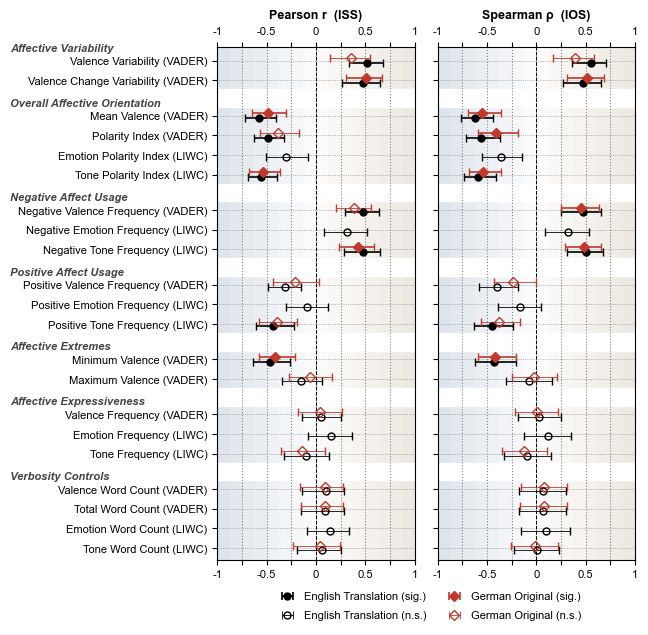

In [ ]:
# ── build y positions with gaps between groups ─────────────────────────────
GAP = 0.8  # larger gap to fit group title text

# ── add significance columns to corr_df ───────────────────────────────────
corr_df['pearson_sig']  = corr_df['pearson_p']  < alpha_corrected
corr_df['spearman_sig'] = corr_df['spearman_p'] < alpha_corrected
measure_to_group = {m: g for g, ms in measure_groups.items() for m in ms}
measures_order = [m for m in final_measures if m in corr_df[MEASURE_COL].unique()]

y_pos = {}
current_y = 0
prev_group = None
group_boundaries = {}   # group_name → (y_bottom, y_top)

for m in reversed(measures_order):
    grp_name = measure_to_group.get(m)
    if prev_group is not None and grp_name != prev_group:
        # record where the previous group ended
        group_boundaries[prev_group] = (group_start_y, current_y - 1)
        current_y += GAP
        group_start_y = current_y
    elif prev_group is None:
        group_start_y = current_y
    y_pos[m] = current_y
    current_y += 1
    prev_group = grp_name

# close last group
group_boundaries[prev_group] = (group_start_y, current_y - 1)

y_max = max(y_pos.values())

fig, axes = plt.subplots(1, 2, figsize=(6.5, 6), sharey=True)
ax_p, ax_s = axes

# ── dots + errorbars ───────────────────────────────────────────────────────
for _, row in corr_df.iterrows():
    m, lang = row['measure'], row['language']
    if m not in y_pos:
        continue
    y     = y_pos[m] + LANG_OFFSET.get(lang, 0)
    fmt   = MARKERS.get(lang, 'o')
    col   = COLORS.get(lang, 'black')

    # Pearson
    sig_p = row['pearson_sig']
    ax_p.errorbar(
        row['pearson'], y,
        xerr=[[row['pearson'] - row['pearson_lo']],
              [row['pearson_hi'] - row['pearson']]],
        fmt=fmt,
        color=col,
        markerfacecolor=col if sig_p else 'none',
        markeredgecolor=col,
        markeredgewidth=1.0,
        markersize=5,
        capsize=3,
        elinewidth=1.2 if sig_p else 0.6,
        capthick=1.2 if sig_p else 0.6,
        zorder=3
    )

    # Spearman
    sig_s = row['spearman_sig']
    ax_s.errorbar(
        row['spearman'], y,
        xerr=[[row['spearman'] - row['spearman_lo']],
              [row['spearman_hi'] - row['spearman']]],
        fmt=fmt,
        color=col,
        markerfacecolor=col if sig_s else 'none',
        markeredgecolor=col,
        markeredgewidth=1.0,
        markersize=5,
        capsize=3,
        elinewidth=1.2 if sig_s else 0.6,
        capthick=1.2 if sig_s else 0.6,
        zorder=3
    )

# ── legend ─────────────────────────────────────────────────────────────────
legend_handles = [
    ax_p.errorbar([-999], [-999], xerr=[[0.15], [0.15]], fmt='o',
                  color='black', markerfacecolor='black', markeredgecolor='black',
                  markersize=5, capsize=3, elinewidth=1.2, capthick=1.2,
                  label='English Translation (sig.)'),
    ax_p.errorbar([-999], [-999], xerr=[[0.15], [0.15]], fmt='o',
                  color='black', markerfacecolor='none', markeredgecolor='black',
                  markersize=5, capsize=3, elinewidth=0.6, capthick=0.6,
                  label='English Translation (n.s.)'),
    ax_p.errorbar([-999], [-999], xerr=[[0.15], [0.15]], fmt='D',
                  color='#c0392b', markerfacecolor='#c0392b', markeredgecolor='#c0392b',
                  markersize=5, capsize=3, elinewidth=1.2, capthick=1.2,
                  label='German Original (sig.)'),
    ax_p.errorbar([-999], [-999], xerr=[[0.15], [0.15]], fmt='D',
                  color='#c0392b', markerfacecolor='none', markeredgecolor='#c0392b',
                  markersize=5, capsize=3, elinewidth=0.6, capthick=0.6,
                  label='German Original (n.s.)'),
]

fig.legend(handles=legend_handles,
           loc='lower center', ncol=2, fontsize=8,
           frameon=False,
           bbox_to_anchor=(0.655, -0.06),
           bbox_transform=fig.transFigure,
           handletextpad=0.5,
           columnspacing=1.5,
           labelspacing=0.8)

# ── group shading + reference lines ───────────────────────────────────────
GROUP_COLORS = ['#dce8f7', '#fdefd4']   # stronger blue / amber

for ax in axes:
    # white stripes in the gaps between groups
    sorted_boundaries = sorted(group_boundaries.values(), key=lambda x: x[0])
    for j in range(len(sorted_boundaries) - 1):
        gap_bottom = sorted_boundaries[j][1] + 0.45    # top of lower group
        gap_top    = sorted_boundaries[j+1][0] - 0.45  # bottom of upper group
        ax.axhspan(gap_bottom, gap_top, color='white', zorder=0)

    # thin dotted horizontal guide lines for every measure
    for m, y in y_pos.items():
        ax.axhline(y, color="#828282", linewidth=0.5,
                   linestyle=':', zorder=1)

# ── group title labels in the gap — left of y-axis only ───────────────────
for i, (grp_name, (y_bot, y_top)) in enumerate(group_boundaries.items()):
    label_y = y_top + GAP * 0.55 + 0.2
    ax_p.text(-3.1, label_y, grp_name,
              fontsize=8, fontstyle='italic', fontweight='bold',
              color='#444444', va='center', ha='left',
              clip_on=False, transform=ax_p.transData, zorder=4)

# ── axes formatting ────────────────────────────────────────────────────────
for ax, title in zip(axes, ["Pearson r  (ISS)",
                              "Spearman ρ  (IOS)"]):
    ax.axvline(0, color='black', linewidth=0.7, linestyle='--', zorder=2)
    ax.set_xlim(-1, 1)

    # title at the top
    ax.set_title(title, fontsize=9, pad=6, fontweight='bold')

    # ticks on both top and bottom
    ax.tick_params(top=True, bottom=True, labeltop=True, labelbottom=True)

    # all tick positions
    all_ticks = [-1, -0.75, -0.5, -0.25, 0, 0.25, 0.5, 0.75, 1]
    labeled_ticks = {-1, -0.5, 0, 0.5, 1}

    ax.set_xticks(all_ticks)
    ax.set_xticklabels(
        [str(v) if v in labeled_ticks else '' for v in all_ticks],
        fontsize=8
    )

    ax.grid(axis='x', which='major', color="#828282", ls=":", linewidth=0.8, zorder=1)
    #ax.spines[['right']].set_visible(False)

    # remove the bottom xlabel (title is now at top via set_title)
    ax.set_xlabel('')

import numpy as np

n_steps = 8

LEFT_COLOR = '#a2b4c8'#gray'#2471a3'# '#c0392b'  # red
RIGHT_COLOR = '#c8b8a2'#gray'#2471a3'#'#2471a3' # blue
for ax in axes:
    # negative side: darker red at -1, fading toward 0
    for i, (x0, x1) in enumerate(zip(
            np.linspace(-1, 0, n_steps + 1)[:-1],
            np.linspace(-1, 0, n_steps + 1)[1:])):
        alpha = 0.05 + 0.3 * (1 - i / (n_steps - 1))
        ax.axvspan(x0, x1, color=LEFT_COLOR, alpha=alpha, zorder=-1, linewidth=0)

    # positive side: darker blue at +1, fading toward 0
    for i, (x0, x1) in enumerate(zip(
            np.linspace(0, 1, n_steps+1)[:-1],
            np.linspace(0, 1, n_steps+1)[1:])):
        alpha = 0.05 + 0.3 * (i / n_steps)              # goes from 0.05 at 0 to 0.80 at +1
        ax.axvspan(x0, x1, color=RIGHT_COLOR, alpha=alpha, zorder=-1, linewidth=0)
        
ax_p.set_yticks([y_pos[m] for m in measures_order])
ax_p.set_yticklabels([measure_title.get(m, m) for m in measures_order], fontsize=8)
ax_p.set_ylim(-0.6, y_max + GAP * 0.9)

fig.subplots_adjust(left=0.28)

fig.tight_layout()
plt.savefig("correlation_dotplot.pdf", bbox_inches='tight')
plt.savefig("correlation_dotplot.png", bbox_inches='tight',dpi=300)

plt.show()

alpha_corr 74 0.0006756756756756757


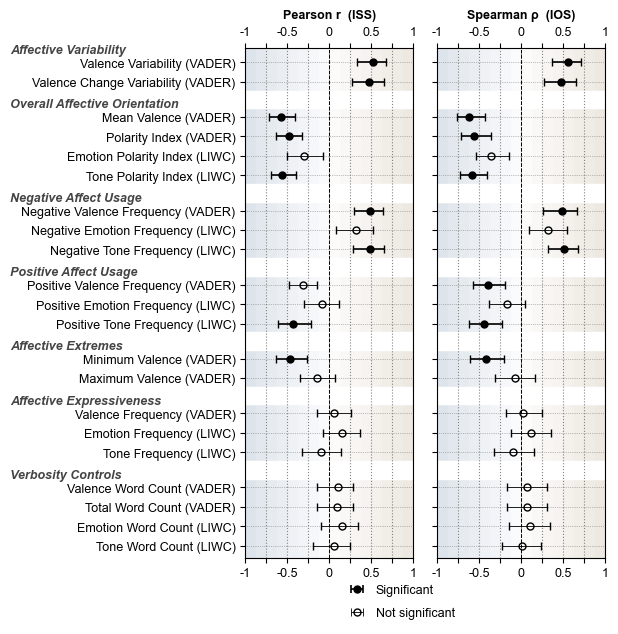

In [ ]:
alpha_corrected = 0.05 / 74
print("alpha_corr", (21 * 2 + 16 * 2), alpha_corrected)
# ── keep English only + add significance columns ──────────────────────────
corr_df = corr_df[corr_df['language'].eq(LANG_ENGLISH)].copy()
corr_df['pearson_sig'] = corr_df['pearson_p'] < alpha_corrected
corr_df['spearman_sig'] = corr_df['spearman_p'] < alpha_corrected

# ── build y positions with gaps between groups ────────────────────────────
GAP = 0.8
measure_to_group = {m: g for g, ms in measure_groups.items() for m in ms}
measures_order = [m for m in final_measures if m in corr_df[MEASURE_COL].unique()]

y_pos, group_boundaries = {}, {}
current_y, prev_group = 0, None

for m in reversed(measures_order):
    grp_name = measure_to_group.get(m)
    if prev_group is not None and grp_name != prev_group:
        group_boundaries[prev_group] = (group_start_y, current_y - 1)
        current_y += GAP
        group_start_y = current_y
    elif prev_group is None:
        group_start_y = current_y
    y_pos[m] = current_y
    current_y += 1
    prev_group = grp_name

group_boundaries[prev_group] = (group_start_y, current_y - 1)
y_max = max(y_pos.values())

fig, axes = plt.subplots(1, 2, figsize=(6.5, 6), sharey=True)
ax_p, ax_s = axes

# ── dots + errorbars: English sig vs n.s. ─────────────────────────────────
fmt = MARKERS.get(LANG_ENGLISH, 'o')
col = COLORS.get(LANG_ENGLISH, 'black')

for _, row in corr_df.iterrows():
    m = row['measure']
    if m not in y_pos:
        continue

    y = y_pos[m]

    sig_p = row['pearson_sig']
    ax_p.errorbar(row['pearson'], y, xerr=[[row['pearson'] - row['pearson_lo']], [row['pearson_hi'] - row['pearson']]], fmt=fmt, color=col, markerfacecolor=col if sig_p else 'none', markeredgecolor=col, markeredgewidth=1.0, markersize=5, capsize=3, elinewidth=1.2 if sig_p else 0.6, capthick=1.2 if sig_p else 0.6, zorder=3)

    sig_s = row['spearman_sig']
    ax_s.errorbar(row['spearman'], y, xerr=[[row['spearman'] - row['spearman_lo']], [row['spearman_hi'] - row['spearman']]], fmt=fmt, color=col, markerfacecolor=col if sig_s else 'none', markeredgecolor=col, markeredgewidth=1.0, markersize=5, capsize=3, elinewidth=1.2 if sig_s else 0.6, capthick=1.2 if sig_s else 0.6, zorder=3)

# ── legend: English significant / not significant only ────────────────────
legend_handles = [
    ax_p.errorbar([-999], [-999], xerr=[[0.15], [0.15]], fmt=fmt, color=col, markerfacecolor=col, markeredgecolor=col, markersize=5, capsize=3, elinewidth=1.2, capthick=1.2, label=f'Significant'),
    ax_p.errorbar([-999], [-999], xerr=[[0.15], [0.15]], fmt=fmt, color=col, markerfacecolor='none', markeredgecolor=col, markersize=5, capsize=3, elinewidth=0.6, capthick=0.6, label='Not significant')
]

fig.legend(handles=legend_handles, loc='lower center', ncol=1, fontsize=9, frameon=False, bbox_to_anchor=(0.655, -0.06), bbox_transform=fig.transFigure, handletextpad=0.5, columnspacing=1.5, labelspacing=0.8)

# ── group shading + reference lines ───────────────────────────────────────
GROUP_COLORS = ['#dce8f7', '#fdefd4']

for ax in axes:
    sorted_boundaries = sorted(group_boundaries.values(), key=lambda x: x[0])
    for j in range(len(sorted_boundaries) - 1):
        ax.axhspan(sorted_boundaries[j][1] + 0.45, sorted_boundaries[j + 1][0] - 0.45, color='white', zorder=0)

    for m, y in y_pos.items():
        ax.axhline(y, color="#828282", linewidth=0.5, linestyle=':', zorder=1)

# ── group title labels ────────────────────────────────────────────────────
for grp_name, (y_bot, y_top) in group_boundaries.items():
    ax_p.text(-3.8, y_top + GAP * 0.55 + 0.2, grp_name, fontsize=9, fontstyle='italic', fontweight='bold', color='#444444', va='center', ha='left', clip_on=False, transform=ax_p.transData, zorder=4)

# ── axes formatting ───────────────────────────────────────────────────────
for ax, title in zip(axes, ["Pearson r  (ISS)", "Spearman ρ  (IOS)"]):
    ax.axvline(0, color='black', linewidth=0.7, linestyle='--', zorder=2)
    ax.set_xlim(-1, 1)
    ax.set_title(title, fontsize=9, pad=6, fontweight='bold')
    ax.tick_params(top=True, bottom=True, labeltop=True, labelbottom=True)

    all_ticks = [-1, -0.75, -0.5, -0.25, 0, 0.25, 0.5, 0.75, 1]
    labeled_ticks = {-1, -0.5, 0, 0.5, 1}
    ax.set_xticks(all_ticks)
    ax.set_xticklabels([str(v) if v in labeled_ticks else '' for v in all_ticks], fontsize=9)
    ax.grid(axis='x', which='major', color="#828282", ls=":", linewidth=0.8, zorder=1)
    ax.set_xlabel('')

import numpy as np

n_steps = 8
LEFT_COLOR = '#a2b4c8'
RIGHT_COLOR = '#c8b8a2'

for ax in axes:
    for i, (x0, x1) in enumerate(zip(np.linspace(-1, 0, n_steps + 1)[:-1], np.linspace(-1, 0, n_steps + 1)[1:])):
        ax.axvspan(x0, x1, color=LEFT_COLOR, alpha=0.05 + 0.3 * (1 - i / (n_steps - 1)), zorder=-1, linewidth=0)

    for i, (x0, x1) in enumerate(zip(np.linspace(0, 1, n_steps + 1)[:-1], np.linspace(0, 1, n_steps + 1)[1:])):
        ax.axvspan(x0, x1, color=RIGHT_COLOR, alpha=0.05 + 0.3 * (i / n_steps), zorder=-1, linewidth=0)

ax_p.set_yticks([y_pos[m] for m in measures_order])
ax_p.set_yticklabels([measure_title.get(m, m) for m in measures_order], fontsize=9)
ax_p.set_ylim(-0.6, y_max + GAP * 0.9)

fig.subplots_adjust(left=0.28)
fig.tight_layout()

plt.savefig("correlation_dotplot_english_sig.pdf", bbox_inches='tight')
plt.savefig("correlation_dotplot_english_sig.png", bbox_inches='tight', dpi=300)
plt.show()